# 04 — Water values

**What this notebook shows.** The water values of the aggregated Swedish reservoir: the marginal value of one more MWh in storage, for every week of the year and every storage level. They come from a stochastic dynamic programme that weighs this week's cost of covering net import, on the price curve of notebook 03, against the expected cost of the future over the inflow scenarios of notebook 02. The notebook checks the solution against economic theory and against changes of the storage grid, and compares the two modelling choices made for its inputs.

All numbers are computed by `watervalues.sdp` from `data/processed/weekly_se.csv`. This is the same code that `uv run watervalues solve` runs to write the water values and the report to `outputs/`.

In [1]:
from watervalues import plots
from watervalues.config import PROJECT_ROOT, load_config
from watervalues.data.build import load_weekly
from watervalues.price import price_table
from watervalues.sdp import (
    build_problem,
    compare_solutions,
    de_price_levels,
    grid_sensitivity,
    sdp_report,
    solve,
    timed_solve,
)

cfg = load_config()
weekly = load_weekly(PROJECT_ROOT / cfg.data.weekly_csv)
solution, seconds = timed_solve(cfg, build_problem(cfg, weekly))
report = "\n".join(sdp_report(cfg, weekly, solution, seconds))
plots.use_style()
print(report[: report.index("Checks")].strip())

Water value SDP: V_t(S) = sum_j pi_j min [C_t(D_t - R) + c_sp Sp + delta V_t+1(S')]; w = -dV/dS [EUR/MWh]
  storage grid: 201 points, 0 to 30,694 GWh (largest storage observed; reference capacity 33,700 GWh), step 153.5 GWh
  inflow scenarios: 11 ISO years (2015-2025), probability 1/J each, independent between weeks
  discount per stage 0.999062 (5% per year); spill penalty 0.01 EUR/MWh
  release: R_max 2,328 GWh per stage; R_min 177 to 1,107 GWh (percentile 5, basis inflow_capped)
  residual demand D_t: 582 to 1,267 GWh per stage
  German price profile (configured): shape without_crisis, mean 73.1 EUR/MWh; the mean of all years, 73.1, includes 2021-2023; the other years average 47.0
  price curve: a_t 55.5 to 109.3 EUR/MWh, b_t 0.0447 to 0.0877 EUR/MWh per GWh
  price at full release p_t(D_t - R_max): -39.1 to 15.3 EUR/MWh, below zero in 39 of 52 weeks (the linear curve beyond the largest observed export, -1,020 GWh); there the model spills rather than sells below -c_sp

Convergence: 

## Method

The state is the stored energy $S$ at the start of a week. For week $t$ the expected cost from now on is

$$V_t(S) = \sum_{j} \pi_j \min_{R,\,Sp} \Big[\, C_t(D_t - R) + c^{sp} Sp + \delta\, V_{t+1}(S') \,\Big], \qquad S' = S + I_{t,j} - R - Sp,$$

with $0 \le S' \le S^{max}$, $\min(R^{min}_t, S + I_{t,j}) \le R \le R^{max}$ and $Sp \ge 0$.

- $C_t(N) = a_t N + \tfrac12 b_t N^2$ is the cost of covering the net import $N = D_t - R$ on the weekly price curve of notebook 03 [kEUR], with $D_t$ the mean residual demand of the week.
- $I_{t,j}$ are the inflow scenarios of notebook 02: one equally likely scenario per historical year, independent between weeks and known before the week's decision.
- $R^{max}$ is the installed hydro capacity times 168 hours times availability; $c^{sp}$ is a tiny spill penalty; $\delta$ is the weekly discount factor of 5 % per year.
- Release and spill are both decisions. Spilling is chosen when producing more would sell below $-c^{sp}$. The linear price curve reaches negative prices before full release in most weeks, because it is extrapolated beyond the largest observed export (see the report above).
- The water value is $w_t(S) = -\partial V_t / \partial S$, in kEUR/GWh, which is the same as EUR/MWh.

The problem is solved backwards over the 52 weeks on a grid of storage levels, vectorised over storage, scenario and next storage. The year is then repeated, with the value at the start of week 1 as the end value, until no water value moves by more than the tolerance between cycles. Only differences of $V$ are meaningful: its level still drifts when the water values have settled.

Two inputs are modelling choices made in this project, and both are compared at the end of the notebook:

- **The minimum release** $R^{min}_t$ is a low percentile, over the years, of $\min(\text{production}, \text{inflow})$ of the week. Forced production (run-of-river, minimum flows, the flood) cannot exceed what flows in that week. A floor on production alone would turn output that follows demand into a physical minimum.
- **The German price profile** has the seasonal shape of the years outside the energy crisis, scaled to the mean of all years (crisis included). Otherwise the gas-price spikes of 2022 would make summer the dearest season.

## Water values by week and storage level

Text(0.0, 1.0, 'Water value of the Swedish reservoir')

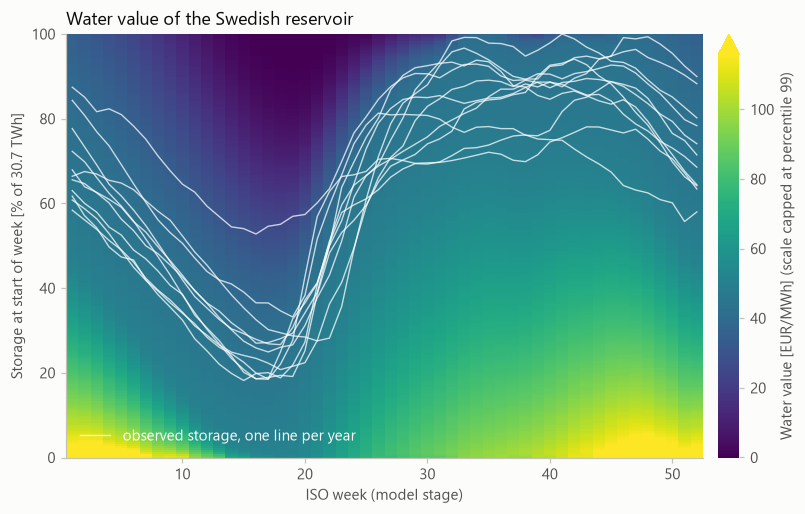

In [2]:
ax = plots.water_value_heatmap(solution.water_value_eur_mwh, solution.problem.storage_gwh, weekly)
ax.set_title("Water value of the Swedish reservoir")

Water is worth most when the reservoir is low in autumn and early winter: little inflow arrives until the snowmelt, and running short means covering demand with expensive imports. Towards the flood the value falls at every level, and during the flood a full reservoir is worth nothing, because more water would only be spilled. Through the summer the values recover as the reservoir has to be filled for the winter.

The observed storage paths of 2015–2025 are drawn for orientation. Whether operating on these water values reproduces them is tested in the backtest of notebook 05.

## Water value curves for selected weeks

Water values [EUR/MWh] by ISO week and storage level [% of S_max]
            10%   25%   50%   75%   90%
iso_week                               
2          99.4  73.0  48.1  42.2  37.1
16         48.0  43.8  30.0  10.0   2.0
30         80.1  69.3  55.5  46.8  42.7
44        102.0  85.5  63.0  47.8  44.8
  all stages and levels: -0.0 to 156.2 EUR/MWh; median 48.1


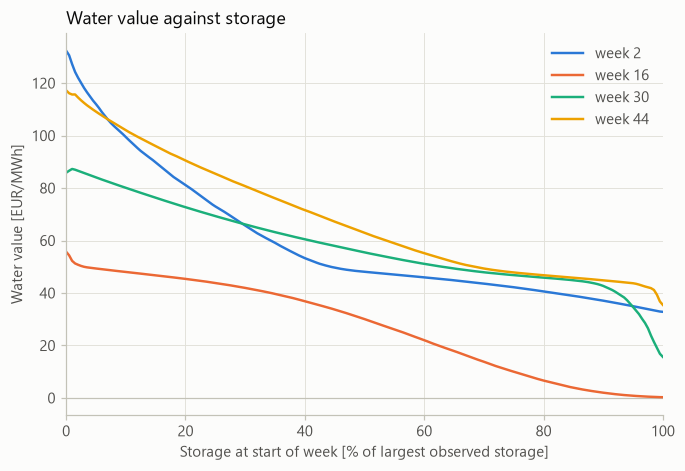

In [3]:
ax = plots.water_value_curves(
    solution.water_value_eur_mwh, solution.problem.storage_gwh, cfg.sdp.curve_weeks
)
ax.set_title("Water value against storage")
print(report[report.index("Water values [EUR/MWh]") :].strip())

In every week the curve falls with storage: the more water is stored, the less the next MWh is worth. The winter curves are steep at low storage, where scarcity bites. Just before the flood the curve is low at every level and reaches zero when the reservoir is full, since spilling is close. Late in the summer a full reservoir keeps a solid value, because it has to last the winter.

The project plan expected water values to be high at the end of winter with a low reservoir and low at the end of summer with a full one. The first part holds only in part: at low storage the values peak in autumn and early winter and are already falling by late winter, because the flood is then only weeks away. A full reservoir at the end of summer is worth much less than a low one in the same weeks, but its value is close to the median of the table, not at the bottom.

## The price equals the discounted water value

In [4]:
print(report[report.index("Checks") : report.index("Water values [EUR/MWh]")].strip())

Checks: water values non-increasing in storage within the grid resolution (3.43 EUR/MWh): yes (0 cells above; largest rise 1.35 EUR/MWh, in week 38 at 0.5% filling)
  water values >= -c_sp (spill is always possible): yes (lowest -0.010 EUR/MWh)
  optimality p_t = delta w_t+1(S') at 90293 interior decisions: 100.00% inside the grid bracket; median |p_t - delta w_t+1| 2.45 EUR/MWh


Setting the derivative of the bracket in $V_t$ with respect to the release to zero gives the key optimality condition: where no bound binds, the price of the week equals the discounted water value of next week,

$$p_t = a_t + b_t (D_t - R^*) = \delta\, w_{t+1}(S').$$

Hydro is produced until it is worth as much sold today as kept for tomorrow. On a grid the condition holds between the one-sided water values, widened by half a storage step of the price curve, and the solver meets it at every interior decision.

- The water values fall with storage everywhere to within the resolution of the grid. The largest rise left sits at a near-empty reservoir (its week and level are printed above) and comes from the kink of the minimum-release rule there.
- No water value is below $-c^{sp}$, since spilling is always possible.

## Convergence of the periodic year

Text(0.0, 1.0, 'Convergence of the yearly cycle')

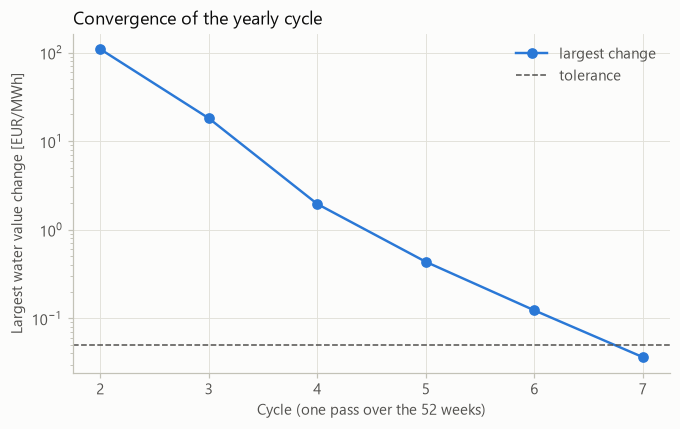

In [5]:
ax = plots.convergence(solution.history_eur_mwh, cfg.sdp.tol_eur_mwh)
ax.set_title("Convergence of the yearly cycle")

The first year starts from an end value of zero, so its water values are far off. Each further cycle shrinks the change several times over. Discounting alone would shrink it only by the yearly discount factor. The faster convergence comes from the reservoir itself: within a year it is drawn down and refilled, so the end value hardly matters for the decisions of the year. A handful of cycles brings every water value within the tolerance.

## Sensitivity to the storage grid

                  max_abs_diff_eur_mwh  mean_abs_diff_eur_mwh
n_storage_points                                             
101                              10.09                   0.50
201                               3.36                   0.13
401                               0.00                   0.00


Text(0.0, 1.0, 'Water value in week 2 on three storage grids')

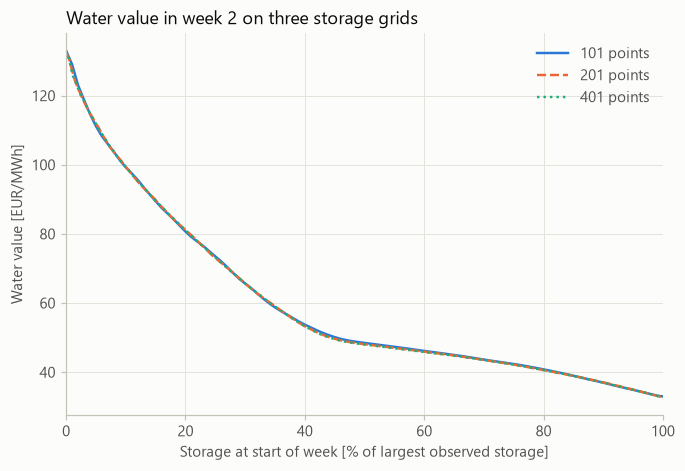

In [6]:
solutions = {
    points: solve(
        build_problem(cfg, weekly, n_storage_points=points), cfg.sdp.tol_eur_mwh, cfg.sdp.max_cycles
    )
    for points in cfg.sdp.grid_sensitivity_points
}
print(grid_sensitivity(solutions, reference=max(solutions)).round(2))
week = cfg.sdp.curve_weeks[0]
curves = {
    f"{points} points": (
        100 * s.problem.storage_gwh / s.problem.capacity_gwh,
        s.water_value_eur_mwh[week - 1],
    )
    for points, s in solutions.items()
}
ax = plots.grid_comparison(curves)
ax.set_title(f"Water value in week {week} on three storage grids")

Halving and doubling the number of storage points changes the water values little. The mean difference against the finest grid is a small fraction of a EUR/MWh. The largest differences are near an empty and near a full reservoir, where the curves bend most. The results do not depend materially on the grid.

## Two modelling choices

In [7]:
levels = de_price_levels(cfg, price_table(weekly, cfg.price_model.seasons))
overrides = {
    "R_min on production": {"reservoir": {"rmin_basis": "production"}},
    "German price shape of all years": {"sdp": {"de_price_shape": "all_years"}},
    "German price level without the crisis": {
        "sdp": {"de_price_level_eur_mwh": levels["without_crisis"]}
    },
}
variants = {"base case": solution}
for label, update in overrides.items():
    section, values = next(iter(update.items()))
    variant = cfg.model_copy(update={section: getattr(cfg, section).model_copy(update=values)})
    variants[label] = timed_solve(variant, build_problem(variant, weekly))[0]
compare_solutions(variants, [(10, 10), (16, 20), (38, 90), (44, 50)]).round(2)

,rising_cells,max_rise_eur_mwh,week 10 at 10%,week 16 at 20%,week 38 at 90%,week 44 at 50%
base case,0,1.35,60.31,45.37,44.65,62.95
R_min on production,50,14.73,61.21,45.68,44.96,64.61
German price shape of all years,0,1.69,57.99,44.89,43.43,58.18
German price level without the crisis,0,1.01,40.62,30.13,29.93,42.65


- **A minimum release on production alone** makes the water values rise with storage at low storage outside the flood season, which fails the sanity check. The cause is the constraint itself. A floor of that size forces water out at this week's price whenever the reservoir runs low, so the marginal MWh is sold at once instead of being kept for the higher value of the coming weeks. Less water then ends up worth less. Removing the floor removes the effect, and a test in `tests/test_sdp.py` pins this. Capping the floor at the week's inflow keeps the forced production of the flood and leaves only a small rise at a near-empty reservoir, from the kink of the floor itself.
- **The shape of the German price profile** moves the water values by a few EUR/MWh, most in the autumn, and leaves the overall pattern unchanged.
- **The level of the German price** matters far more. At the average of the years outside the crisis, the water values fall roughly in proportion to the price. This is the continental price scenario of notebook 05.

## Limitations

- **One aggregated reservoir.** Sweden is modelled as one reservoir, with no transmission limits between the northern zones, where the water is, and the southern ones, where the load is.
- **Independent weeks.** Inflow is independent from week to week, with eleven historical scenarios: a dry spell does not make the next week drier, and no year drier than the record appears.
- **Fixed demand and German price.** Residual demand and the German price are set at their weekly means; the only uncertainty is inflow.
- **A linear price curve.** The curve is extrapolated beyond the largest observed export, where it gives negative prices; the model spills there instead.
- **A grid for the next storage.** The next storage is restricted to the grid, so a decision can waste up to one storage step of water.
- **Spill is not observed.** The inflow that the scenarios are built from is therefore underestimated in very wet weeks.